**A. Isolation Forest**

*Best starting algorithm for anomaly detection.*

  Why?
- Designed specifically for anomalies
- Fast on large datasets
- Works well without labeled data
- Easy to implement
- Use For
  - Fraud transaction detection
  - Outlier financial records
  - GL anomaly detection
- Python Library
  - from sklearn.ensemble import IsolationForest


📊 Isolation Forest Results
----------------------------------
Accuracy   : 0.9894
Precision  : 0.0013
Recall     : 0.0214
F1-Score   : 0.0024
ROC-AUC    : 0.2659

📌 Confusion Matrix
[[310868   3138]
 [   183      4]]

✅ Results saved to model_results.csv


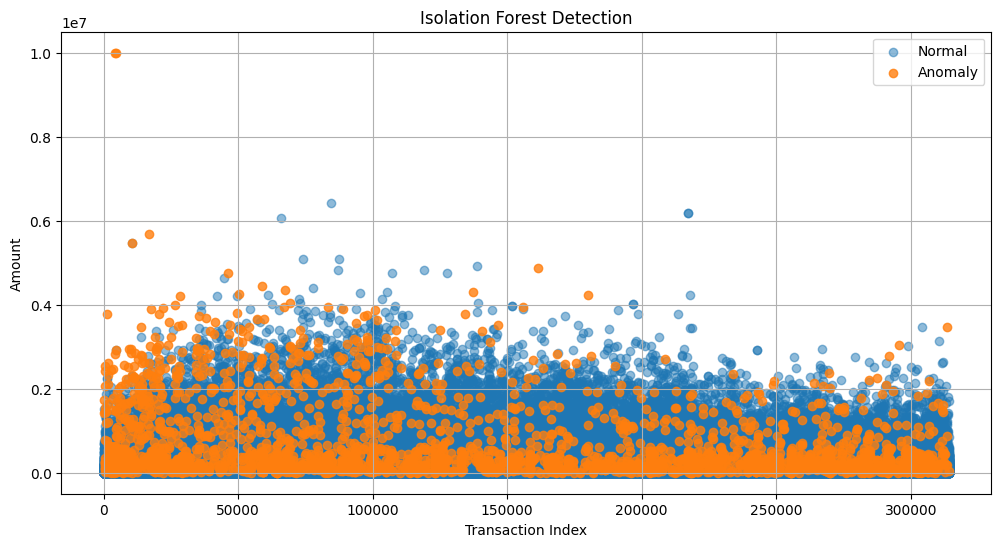

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

# =========================
# 🔥 HANDLE MISSING VALUES
# =========================

# Remove rows where target is missing
df = df.dropna(subset=['isFraud'])

# Convert target to integer (important)
df['isFraud'] = df['isFraud'].astype(int)

# Fill missing feature values
df = df.fillna(0)

# =========================
# ENCODE CATEGORICAL
# =========================
le = LabelEncoder()
df['type'] = le.fit_transform(df['type'])

# =========================
# FEATURE SELECTION
# =========================
features = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

X = df[features]
y_true = df['isFraud']

# =========================
# TRAIN MODEL
# =========================
model = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42
)

df['anomaly'] = model.fit_predict(X)

# Convert labels: 1→0 (Normal), -1→1 (Fraud)
df['anomaly'] = df['anomaly'].map({1: 0, -1: 1})

y_pred = df['anomaly']

# =========================
# 🔥 FINAL SAFETY CHECK
# =========================

# Remove any remaining NaN just in case
mask = (~y_true.isna()) & (~y_pred.isna())
y_true = y_true[mask]
y_pred = y_pred[mask]

# =========================
# EVALUATION METRICS
# =========================

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

# Use anomaly scores for ROC-AUC
scores = model.decision_function(X)
roc_auc = roc_auc_score(y_true, scores)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# =========================
# PRINT RESULTS
# =========================

print("\n📊 Isolation Forest Results")
print("----------------------------------")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix")
print(cm)

# =========================
# SAVE RESULTS TABLE
# =========================

results_df = pd.DataFrame({
    "Model": ["Isolation Forest"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("model_results.csv", index=False)

print("\n✅ Results saved to model_results.csv")

# =========================
# VISUALIZATION
# =========================

normal = df[df['anomaly'] == 0]
anomaly = df[df['anomaly'] == 1]

plt.figure(figsize=(12,6))

plt.scatter(normal.index, normal['amount'], label='Normal', alpha=0.5)
plt.scatter(anomaly.index, anomaly['amount'], label='Anomaly', alpha=0.8)

plt.title("Isolation Forest Detection")
plt.xlabel("Transaction Index")
plt.ylabel("Amount")
plt.legend()
plt.grid(True)

plt.show()

**B-One-Class SVM**

*Very popular anomaly detection algorithm.*

  Why?
- Learns normal behavior
- Detects unusual patterns
- Limitation: Slow on very large datasets
- Use For: Small-medium datasets
- Library
- from sklearn.svm import OneClassSVM

Original shape: (30804, 12)
Fraud rate: 0.2727%

Training One-Class SVM on 30719 normal samples...

📊 One-Class SVM Results (Corrected)
Accuracy   : 0.9877
Precision  : 0.0489
Recall     : 0.1905
F1-Score   : 0.0779
ROC-AUC    : 0.5668

📌 Confusion Matrix:
[[30408   311]
 [   68    16]]

📋 Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99     30719
       Fraud       0.05      0.19      0.08        84

    accuracy                           0.99     30803
   macro avg       0.52      0.59      0.54     30803
weighted avg       1.00      0.99      0.99     30803


✅ Results saved to svm_results.csv


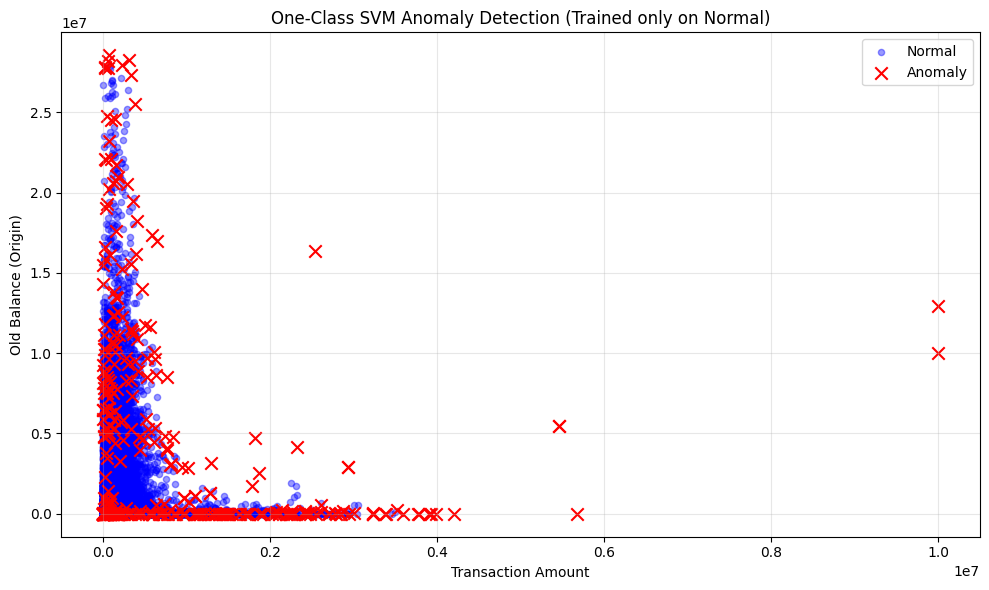

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

print("Original shape:", df.shape)
print("Fraud rate: {:.4f}%".format(df['isFraud'].mean() * 100))

# =========================
# HANDLE MISSING VALUES
# =========================
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

# Fill numerical missing values with median (better than 0)
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# =========================
# FEATURE ENGINEERING
# =========================
# Keep only useful features (remove high-cardinality IDs)
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

# Encode only the 'type' column
le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y_true = df["isFraud"]

# =========================
# SCALING
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================
# TRAIN ONLY ON NORMAL DATA (Important!)
# =========================
X_normal = X_scaled[y_true == 0]

print(f"\nTraining One-Class SVM on {len(X_normal)} normal samples...")

model = OneClassSVM(
    kernel='rbf',
    gamma='scale',      # better than 'auto'
    nu=0.01,            # adjust according to your real fraud rate
    verbose=False
)

model.fit(X_normal)     # ← Train ONLY on normal data

# =========================
# PREDICTIONS ON FULL DATA
# =========================
raw_pred = model.predict(X_scaled)          # 1 = normal, -1 = anomaly
y_pred = np.where(raw_pred == -1, 1, 0)     # Convert to 0/1

# Decision scores (higher = more normal)
scores = model.decision_function(X_scaled)

# =========================
# EVALUATION
# =========================
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)

# Important: invert scores for ROC-AUC
roc_auc = roc_auc_score(y_true, -scores)

cm = confusion_matrix(y_true, y_pred)

print("\n" + "="*50)
print("📊 One-Class SVM Results (Corrected)")
print("="*50)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Fraud"]))

# =========================
# SAVE RESULTS
# =========================
results_df = pd.DataFrame({
    "Model": ["One-Class SVM"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("svm_results.csv", index=False)
print("\n✅ Results saved to svm_results.csv")

# =========================
# VISUALIZATION
# =========================
plt.figure(figsize=(10, 6))

normal_mask = y_pred == 0
anomaly_mask = y_pred == 1

plt.scatter(df.loc[normal_mask, "amount"],
            df.loc[normal_mask, "oldbalanceOrg"],
            c='blue', alpha=0.4, label="Normal", s=20)

plt.scatter(df.loc[anomaly_mask, "amount"],
            df.loc[anomaly_mask, "oldbalanceOrg"],
            c='red', marker='x', s=80, label="Anomaly")

plt.xlabel("Transaction Amount")
plt.ylabel("Old Balance (Origin)")
plt.title("One-Class SVM Anomaly Detection (Trained only on Normal)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C. Local Outlier Factor (LOF)

Detects anomalies based on neighborhood density.

Why?
Good for local anomalies
Strong unsupervised method
Library
from sklearn.neighbors import LocalOutlierFactor
D. Decision Tree / Random Forest

Use if dataset has labels.

Why?
Explainable
Auditors like interpretable models
Library
from sklearn.ensemble import RandomForestClassifier

Original shape: (46125, 12)
Fraud rate: 0.2038%

Training Local Outlier Factor on 46030 normal samples...

📊 Local Outlier Factor (LOF) Results
Accuracy   : 0.9903
Precision  : 0.0267
Recall     : 0.1064
F1-Score   : 0.0426
ROC-AUC    : 0.5634

📌 Confusion Matrix:
[[45665   365]
 [   84    10]]

📋 Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00     46030
       Fraud       0.03      0.11      0.04        94

    accuracy                           0.99     46124
   macro avg       0.51      0.55      0.52     46124
weighted avg       1.00      0.99      0.99     46124


✅ Results saved to lof_results.csv


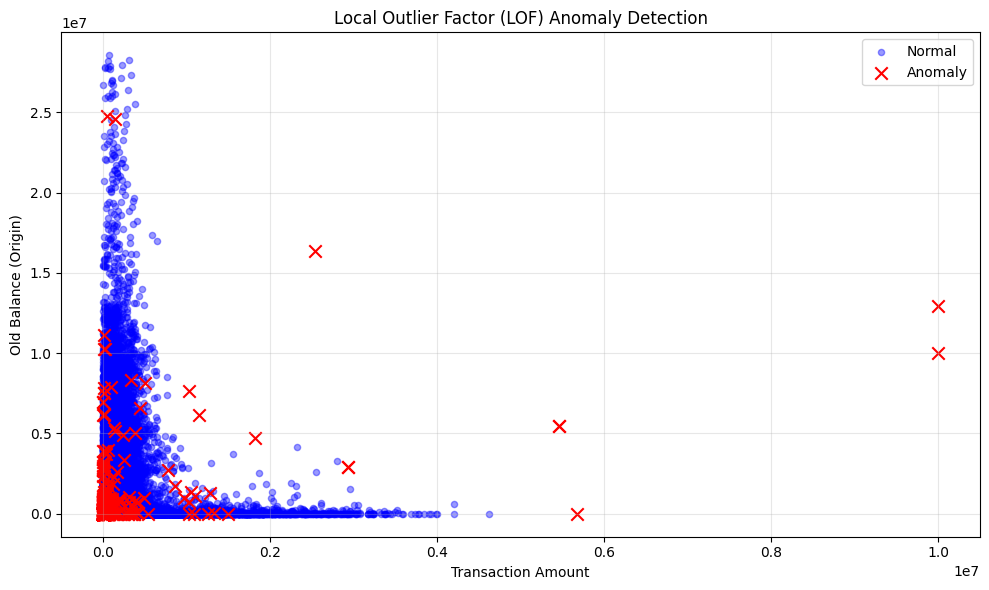

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

print("Original shape:", df.shape)
print("Fraud rate: {:.4f}%".format(df['isFraud'].mean() * 100))

# =========================
# HANDLE MISSING VALUES
# =========================
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# =========================
# FEATURE ENGINEERING
# =========================
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y_true = df["isFraud"]

# =========================
# SCALING
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================
# TRAIN ONLY ON NORMAL DATA (Recommended)
# =========================
X_normal = X_scaled[y_true == 0]

print(f"\nTraining Local Outlier Factor on {len(X_normal)} normal samples...")

model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01,      # adjust according to your fraud rate
    novelty=True,            # Important for prediction on new data
    n_jobs=-1
)

model.fit(X_normal)

# =========================
# PREDICTIONS
# =========================
raw_pred = model.predict(X_scaled)          # 1 = normal, -1 = anomaly
y_pred = np.where(raw_pred == -1, 1, 0)

# Decision scores (higher = more normal) → invert for ROC-AUC
scores = model.decision_function(X_scaled)

# =========================
# EVALUATION
# =========================
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)
roc_auc   = roc_auc_score(y_true, -scores)

cm = confusion_matrix(y_true, y_pred)

print("\n" + "="*55)
print("📊 Local Outlier Factor (LOF) Results")
print("="*55)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Fraud"]))

# =========================
# SAVE RESULTS
# =========================
results_df = pd.DataFrame({
    "Model": ["Local Outlier Factor"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("lof_results.csv", index=False)
print("\n✅ Results saved to lof_results.csv")

# =========================
# VISUALIZATION
# =========================
plt.figure(figsize=(10, 6))

normal_mask = y_pred == 0
anomaly_mask = y_pred == 1

plt.scatter(df.loc[normal_mask, "amount"],
            df.loc[normal_mask, "oldbalanceOrg"],
            c='blue', alpha=0.4, label="Normal", s=20)

plt.scatter(df.loc[anomaly_mask, "amount"],
            df.loc[anomaly_mask, "oldbalanceOrg"],
            c='red', marker='x', s=80, label="Anomaly")

plt.xlabel("Transaction Amount")
plt.ylabel("Old Balance (Origin)")
plt.title("Local Outlier Factor (LOF) Anomaly Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

A. Autoencoder

This should be your MAIN MODEL.

Why Autoencoder?

Because:

Excellent for anomaly detection
Learns normal transaction behavior
High reconstruction error = anomaly
Works very well on financial data
How It Works

Normal data reconstructs well.

Anomalies reconstruct poorly.

Difference:

Input → Encoder → Decoder → Reconstruction Error

Large error = anomaly.

Original shape: (46125, 12)
Fraud rate: 0.2038%

Training Autoencoder on 36824 normal samples...
Epoch 1/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.1781 - val_loss: 0.0263
Epoch 2/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0643 - val_loss: 0.0342
Epoch 3/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0522 - val_loss: 0.0208
Epoch 4/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0449 - val_loss: 0.0259
Epoch 5/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0394 - val_loss: 0.0253
Epoch 6/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0361 - val_loss: 0.0164
Epoch 7/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0323 - val_loss: 0.0167
Epoch 8/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0305 - val_loss: 0.0252
Epoch 9/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0301 - val_loss: 0.0227
Epoch 10/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0283 - val_loss: 0.0224
Epoch 11/100
576/576 ━━━━━━━━━━━

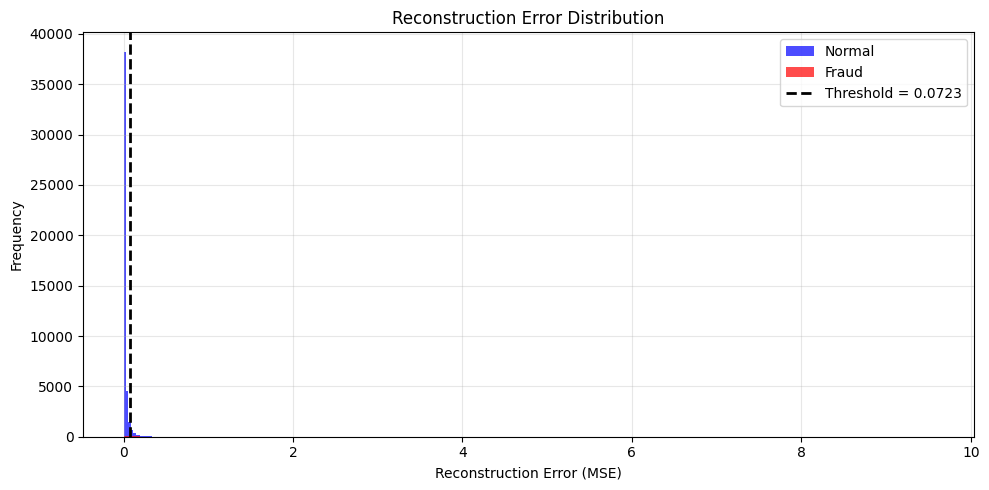

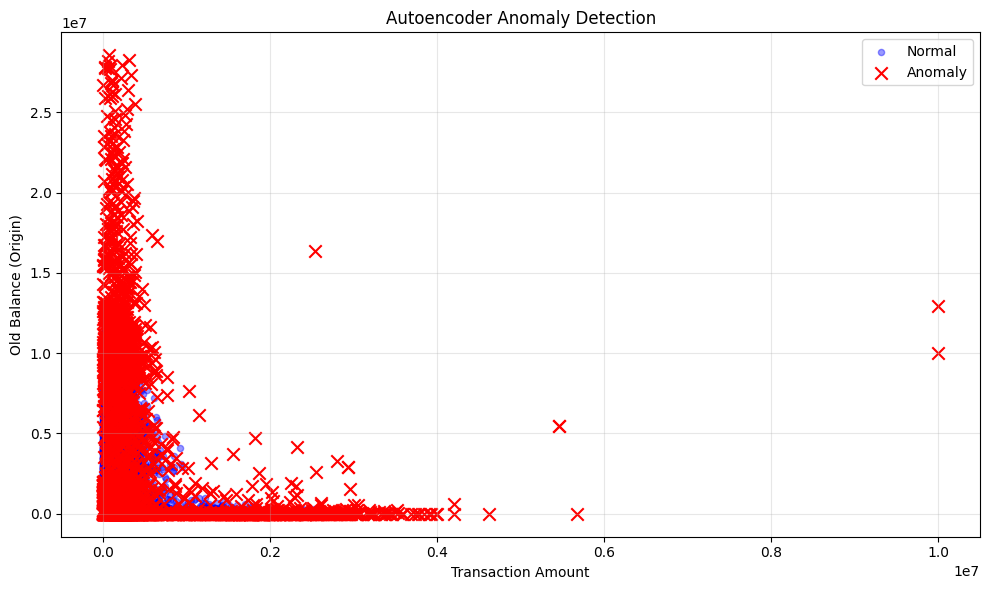

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

print("Original shape:", df.shape)
print("Fraud rate: {:.4f}%".format(df['isFraud'].mean() * 100))

# =========================
# HANDLE MISSING VALUES
# =========================
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# =========================
# FEATURE ENGINEERING
# =========================
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y_true = df["isFraud"]

# =========================
# SCALING
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================
# TRAIN ONLY ON NORMAL DATA
# =========================
X_normal = X_scaled[y_true == 0]

X_train, X_val = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

print(f"\nTraining Autoencoder on {len(X_train)} normal samples...")

# =========================
# BUILD AUTOENCODER
# =========================
input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
x = Dense(64, activation='relu')(input_layer)
x = Dropout(0.1)(x)
x = Dense(32, activation='relu')(x)
x = Dropout(0.1)(x)
latent = Dense(16, activation='relu')(x)

# Decoder
x = Dense(32, activation='relu')(latent)
x = Dropout(0.1)(x)
x = Dense(64, activation='relu')(x)
output_layer = Dense(input_dim, activation='linear')(x)

autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer='adam', loss='mse')

# =========================
# TRAIN MODEL
# =========================
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

history = autoencoder.fit(
    X_train, X_train,
    epochs=100,
    batch_size=64,
    validation_data=(X_val, X_val),
    callbacks=[early_stop],
    verbose=1
)

# =========================
# RECONSTRUCTION ERROR
# =========================
X_pred = autoencoder.predict(X_scaled, verbose=0)
mse = np.mean(np.square(X_scaled - X_pred), axis=1)

# =========================
# THRESHOLD (95th percentile of normal data)
# =========================
normal_mse = mse[y_true == 0]
threshold = np.percentile(normal_mse, 95)

print(f"\nThreshold (95th percentile): {threshold:.6f}")

# Predictions
y_pred = (mse > threshold).astype(int)

# =========================
# EVALUATION METRICS
# =========================
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)
roc_auc   = roc_auc_score(y_true, mse)          # higher error = more anomalous

cm = confusion_matrix(y_true, y_pred)

print("\n" + "="*55)
print("📊 Autoencoder Results")
print("="*55)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Fraud"]))

# =========================
# SAVE RESULTS
# =========================
results_df = pd.DataFrame({
    "Model": ["Autoencoder"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("autoencoder_results.csv", index=False)
print("\n✅ Results saved to autoencoder_results.csv")

# Also save detailed reconstruction errors
detailed = pd.DataFrame({
    "Reconstruction_Error": mse,
    "True_Label": y_true,
    "Predicted_Anomaly": y_pred
})
detailed.to_csv("autoencoder_detailed_results.csv", index=False)

# =========================
# VISUALIZATIONS
# =========================

# 1. Reconstruction Error Distribution
plt.figure(figsize=(10, 5))
plt.hist(mse[y_true == 0], bins=50, alpha=0.7, label="Normal", color="blue")
plt.hist(mse[y_true == 1], bins=50, alpha=0.7, label="Fraud", color="red")
plt.axvline(threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold = {threshold:.4f}")
plt.title("Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Scatter plot (same style as previous models)
plt.figure(figsize=(10, 6))

normal_mask = y_pred == 0
anomaly_mask = y_pred == 1

plt.scatter(df.loc[normal_mask, "amount"],
            df.loc[normal_mask, "oldbalanceOrg"],
            c='blue', alpha=0.4, label="Normal", s=20)

plt.scatter(df.loc[anomaly_mask, "amount"],
            df.loc[anomaly_mask, "oldbalanceOrg"],
            c='red', marker='x', s=80, label="Anomaly")

plt.xlabel("Transaction Amount")
plt.ylabel("Old Balance (Origin)")
plt.title("Autoencoder Anomaly Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# LSTM Autoencoder for Anomaly Detection

## 1. Introduction

An **LSTM Autoencoder** is a type of neural network designed for **unsupervised learning**, particularly useful for **time-series anomaly detection**.

It combines:

* **LSTM (Long Short-Term Memory)** → handles sequential/time-based data
* **Autoencoder architecture** → learns to reconstruct input data

The goal is:

> Learn normal patterns → detect abnormal behavior based on reconstruction error

---

## 2. Why Use LSTM Autoencoder?

Traditional machine learning models fail when:

* Data is sequential (time-dependent)
* Patterns depend on previous values
* Order of events matters

### LSTM solves this by:

* Remembering long-term dependencies
* Understanding sequence behavior
* Capturing temporal patterns

### Autoencoder helps by:

* Learning compressed representation
* Reconstructing input data
* Highlighting anomalies via reconstruction error

---

## 3. Key Concepts

### 3.1 Time-Series Data

Data where:

* Order matters
* Values depend on previous values

Examples:

* Daily transactions
* Stock prices
* Banking activity logs

---

### 3.2 LSTM (Long Short-Term Memory)

LSTM is a special type of RNN that solves:

* Vanishing gradient problem
* Long-term dependency learning

#### Components:

* Forget Gate
* Input Gate
* Output Gate
* Cell State

---

### 3.3 Autoencoder Architecture

An autoencoder has two parts:

#### Encoder:

Compresses input sequence into a latent representation

#### Decoder:

Reconstructs the original sequence from compressed form

---

## 4. How LSTM Autoencoder Works

### Step-by-Step Process:

1. Input sequence is fed into encoder LSTM
2. Encoder compresses sequence into latent vector
3. Decoder reconstructs sequence
4. Calculate reconstruction error:

   * Mean Squared Error (MSE)

---

## 5. Anomaly Detection Logic

### Training Phase:

* Train only on **normal data**

### Testing Phase:

* Input new data
* Compute reconstruction error

### Decision Rule:

```
If error > threshold → anomaly
Else → normal
```

---

## 6. Why It Works for Fraud Detection

Fraudulent behavior:

* Deviates from normal patterns
* Has unusual sequence behavior

LSTM captures:

* Spending patterns
* Transaction intervals
* Behavioral sequences

Autoencoder detects:

* Unusual reconstruction errors

---

## 7. Applications

### Banking & Finance:

* Credit card fraud detection
* Transaction monitoring
* Account misuse detection

### Other Fields:

* IoT anomaly detection
* Predictive maintenance
* Network intrusion detection

---

## 8. Advantages

* Works on unlabeled data
* Learns temporal patterns
* Detects unknown anomalies
* Effective for real-time systems

---

## 9. Limitations

* Requires large normal dataset
* Sensitive to threshold selection
* Computationally expensive
* Hard to interpret

---

## 10. Evaluation Metrics

* Reconstruction Error (MSE)
* Precision / Recall
* ROC-AUC (if labels available)

---

## 11. Summary

LSTM Autoencoder is ideal for:

* Sequential anomaly detection
* Time-series fraud detection
* Behavioral pattern analysis

It works by:

> Learning normal sequences → flagging abnormal ones

---

## 12. Best Use Cases

* Credit card fraud detection
* Banking transaction streams
* Real-time anomaly detection systems

---


Original shape: (46125, 12)
Fraud rate: 0.2038%

Total sequences created: 46104
Training LSTM Autoencoder on 36809 normal sequences...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 20, 7)          │           455 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,911 (202.78 KB)

 Trainable params: 51,911 (202.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 31s 41ms/step - loss: 0.5839 - val_loss: 0.4543
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 39s 37ms/step - loss: 0.4762 - val_loss: 0.4339
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 42s 38ms/step - loss: 0.6622 - val_loss: 0.4264
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 40s 37ms/step - loss: 0.4546 - val_loss: 0.4059
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 41s 38ms/step - loss: 0.4441 - val_loss: 0.3996
Epoch 6/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 40s 37ms/step - loss: 0.4401 - val_loss: 0.3905
Epoch 7/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 23s 41ms/step - loss: 0.4273 - val_loss: 0.3807
Epoch 8/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 23s 39ms/step - loss: 0.4177 - val_loss: 0.3674
Epoch 9/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 24s 41ms/step - loss: 0.4146 - val_loss: 0.3628
Epoch 10/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 22s 37ms/step - loss: 0.4036 - val_loss: 0.3464
Epoch 11/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 41s 38ms/step - loss: 0.3934 - val_loss: 0.3401
Epoch 12/50
576/576 ━━━━━━━━━━

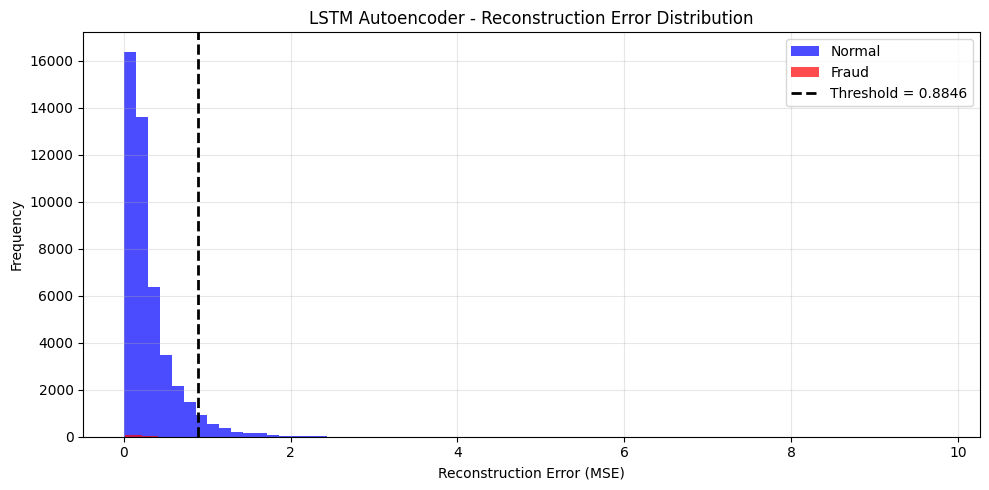

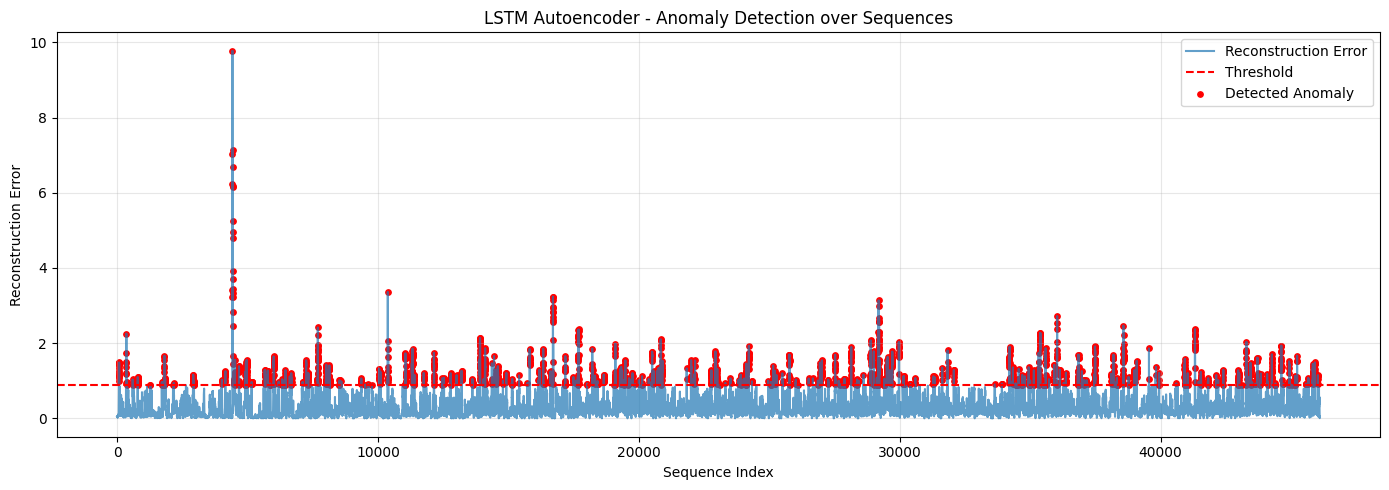

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

print("Original shape:", df.shape)
print("Fraud rate: {:.4f}%".format(df['isFraud'].mean() * 100))

# =========================
# HANDLE MISSING VALUES
# =========================
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# =========================
# FEATURE ENGINEERING
# =========================
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y_true = df["isFraud"].values

# =========================
# SCALING
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================
# CREATE SEQUENCES
# =========================
def create_sequences(data, labels, seq_length=20):
    Xs, ys = [], []
    for i in range(len(data) - seq_length):
        Xs.append(data[i:i+seq_length])
        # Take the label of the LAST transaction in the sequence
        ys.append(labels[i+seq_length-1])
    return np.array(Xs), np.array(ys)

SEQ_LEN = 20
X_seq, y_seq = create_sequences(X_scaled, y_true, SEQ_LEN)

print(f"\nTotal sequences created: {len(X_seq)}")

# =========================
# TRAIN ONLY ON NORMAL SEQUENCES
# =========================
normal_idx = np.where(y_seq == 0)[0]
X_normal = X_seq[normal_idx]

X_train, X_val = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

print(f"Training LSTM Autoencoder on {len(X_train)} normal sequences...")

# =========================
# BUILD LSTM AUTOENCODER
# =========================
n_features = X_seq.shape[2]

model = Sequential([
    LSTM(64, activation='relu', input_shape=(SEQ_LEN, n_features), return_sequences=False),
    Dropout(0.2),
    RepeatVector(SEQ_LEN),
    LSTM(64, activation='relu', return_sequences=True),
    Dropout(0.2),
    TimeDistributed(Dense(n_features))
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# =========================
# TRAIN MODEL
# =========================
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train, X_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, X_val),
    callbacks=[early_stop],
    verbose=1
)

# =========================
# RECONSTRUCTION ERROR ON ALL SEQUENCES
# =========================
X_pred = model.predict(X_seq, verbose=0)

# Mean squared error per sequence
mse = np.mean(np.power(X_seq - X_pred, 2), axis=(1, 2))

# =========================
# THRESHOLD (from normal sequences only)
# =========================
normal_mse = mse[y_seq == 0]
threshold = np.percentile(normal_mse, 95)

print(f"\nThreshold (95th percentile of normal): {threshold:.6f}")

# Predictions
y_pred = (mse > threshold).astype(int)

# =========================
# EVALUATION METRICS
# =========================
accuracy  = accuracy_score(y_seq, y_pred)
precision = precision_score(y_seq, y_pred, zero_division=0)
recall    = recall_score(y_seq, y_pred, zero_division=0)
f1        = f1_score(y_seq, y_pred, zero_division=0)
roc_auc   = roc_auc_score(y_seq, mse)

cm = confusion_matrix(y_seq, y_pred)

print("\n" + "="*55)
print("📊 LSTM Autoencoder Results")
print("="*55)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(y_seq, y_pred, target_names=["Normal", "Fraud"]))

# =========================
# SAVE RESULTS
# =========================
results_df = pd.DataFrame({
    "Model": ["LSTM Autoencoder"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("lstm_autoencoder_results.csv", index=False)
print("\n✅ Results saved to lstm_autoencoder_results.csv")

# =========================
# VISUALIZATIONS
# =========================

# 1. Reconstruction Error Distribution
plt.figure(figsize=(10, 5))
plt.hist(mse[y_seq == 0], bins=50, alpha=0.7, label="Normal", color="blue")
plt.hist(mse[y_seq == 1], bins=50, alpha=0.7, label="Fraud", color="red")
plt.axvline(threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold = {threshold:.4f}")
plt.title("LSTM Autoencoder - Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Error over sequences
plt.figure(figsize=(14, 5))
plt.plot(mse, label="Reconstruction Error", alpha=0.7)
plt.axhline(threshold, color="red", linestyle="--", label="Threshold")
plt.scatter(np.where(y_pred == 1)[0], mse[y_pred == 1],
            color="red", s=15, label="Detected Anomaly")
plt.title("LSTM Autoencoder - Anomaly Detection over Sequences")
plt.xlabel("Sequence Index")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

A. DBSCAN (HIGHLY RECOMMENDED)
Why?
Detects noise/outliers automatically
No need for labeled data
Excellent for anomaly detection
Use

Transactions outside clusters = anomalies

Library
from sklearn.cluster import DBSCAN

Original shape: (46125, 12)
Fraud rate: 0.2038%

Training DBSCAN...
Number of clusters found : 11
Number of anomalies (noise): 1160

📊 DBSCAN Results
Accuracy   : 0.9733
Precision  : 0.0103
Recall     : 0.1277
F1-Score   : 0.0191
ROC-AUC    : 0.5555

📌 Confusion Matrix:
[[44882  1148]
 [   82    12]]

📋 Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     46030
       Fraud       0.01      0.13      0.02        94

    accuracy                           0.97     46124
   macro avg       0.50      0.55      0.50     46124
weighted avg       1.00      0.97      0.98     46124


✅ Results saved to dbscan_results.csv


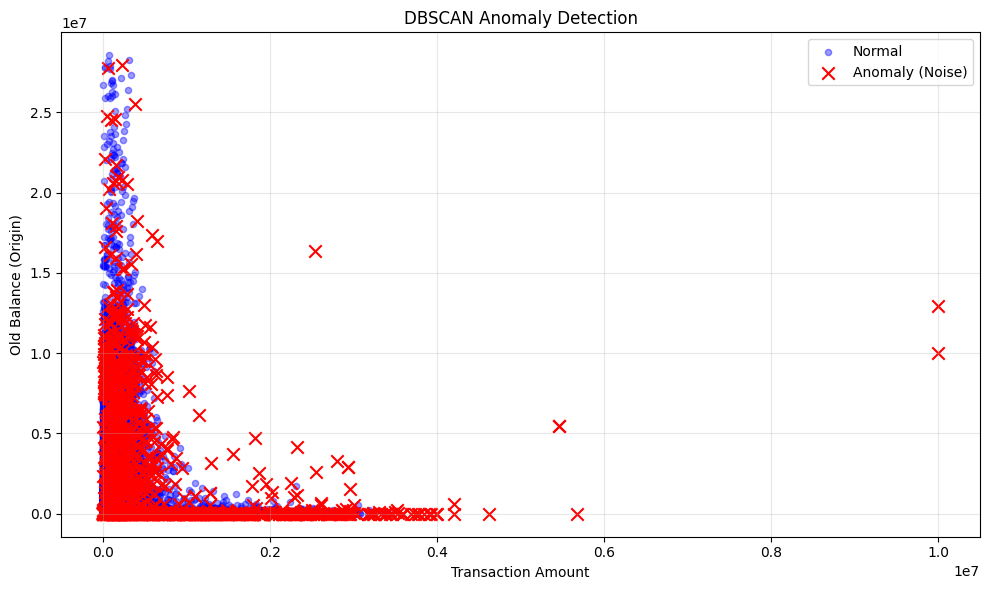

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
from sklearn.neighbors import NearestNeighbors

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

print("Original shape:", df.shape)
print("Fraud rate: {:.4f}%".format(df['isFraud'].mean() * 100))

# =========================
# HANDLE MISSING VALUES
# =========================
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# =========================
# FEATURE ENGINEERING
# =========================
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y_true = df["isFraud"]

# =========================
# SCALING (Very important for DBSCAN)
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================
# FIND GOOD eps VALUE (Optional but recommended)
# =========================
# Uncomment the lines below if you want to visualize the k-distance graph
# to choose a better eps value.

# neighbors = NearestNeighbors(n_neighbors=10)
# neighbors_fit = neighbors.fit(X_scaled)
# distances, _ = neighbors_fit.kneighbors(X_scaled)
# distances = np.sort(distances[:, -1])

# plt.figure(figsize=(10, 5))
# plt.plot(distances)
# plt.title("k-Distance Graph (help choose eps)")
# plt.xlabel("Points sorted by distance")
# plt.ylabel("10th Neighbor Distance")
# plt.grid(True)
# plt.show()

# =========================
# TRAIN DBSCAN
# =========================
print("\nTraining DBSCAN...")

model = DBSCAN(
    eps=0.8,              # ← Most important parameter (try 0.5 to 1.5)
    min_samples=10,       # ← Minimum points to form a dense region
    metric='euclidean',
    n_jobs=-1
)

labels = model.fit_predict(X_scaled)

# DBSCAN labels:
#  -1  → Noise / Outlier  → Anomaly (1)
#  >=0 → Cluster member   → Normal  (0)

y_pred = np.where(labels == -1, 1, 0)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Number of clusters found : {n_clusters}")
print(f"Number of anomalies (noise): {n_noise}")

# =========================
# ANOMALY SCORE (for ROC-AUC)
# =========================
# We use distance to the nearest core point as anomaly score
core_samples = model.components_

if len(core_samples) > 0:
    nn = NearestNeighbors(n_neighbors=1)
    nn.fit(core_samples)
    distances, _ = nn.kneighbors(X_scaled)
    anomaly_scores = distances.ravel()          # higher distance = more anomalous
else:
    anomaly_scores = np.zeros(len(X_scaled))

# =========================
# EVALUATION METRICS
# =========================
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)
roc_auc   = roc_auc_score(y_true, anomaly_scores)

cm = confusion_matrix(y_true, y_pred)

print("\n" + "="*55)
print("📊 DBSCAN Results")
print("="*55)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Fraud"]))

# =========================
# SAVE RESULTS
# =========================
results_df = pd.DataFrame({
    "Model": ["DBSCAN"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("dbscan_results.csv", index=False)
print("\n✅ Results saved to dbscan_results.csv")

# =========================
# VISUALIZATION
# =========================
plt.figure(figsize=(10, 6))

normal_mask = y_pred == 0
anomaly_mask = y_pred == 1

plt.scatter(df.loc[normal_mask, "amount"],
            df.loc[normal_mask, "oldbalanceOrg"],
            c='blue', alpha=0.4, label="Normal", s=20)

plt.scatter(df.loc[anomaly_mask, "amount"],
            df.loc[anomaly_mask, "oldbalanceOrg"],
            c='red', marker='x', s=80, label="Anomaly (Noise)")

plt.xlabel("Transaction Amount")
plt.ylabel("Old Balance (Origin)")
plt.title("DBSCAN Anomaly Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

B. K-Means

Simple clustering algorithm.

Why?
Easy to implement
Good comparison baseline
Limitation
Weak on complex anomalies
4. Graph-Based Algorithms (Optional but Powerful)

If you want innovation in your proposal:

Use:
NetworkX
Graph Neural Networks (advanced)
Example

Accounts = nodes
Transactions = edges

Suspicious connections become detectable

Original shape: (46125, 12)
Fraud rate: 0.2038%

Training K-Means on 46030 normal samples...
Threshold (95th percentile): 2.512853

📊 K-Means Results
Accuracy   : 0.9483
Precision  : 0.0056
Recall     : 0.1383
F1-Score   : 0.0108
ROC-AUC    : 0.7629

📌 Confusion Matrix:
[[43728  2302]
 [   81    13]]

📋 Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     46030
       Fraud       0.01      0.14      0.01        94

    accuracy                           0.95     46124
   macro avg       0.50      0.54      0.49     46124
weighted avg       1.00      0.95      0.97     46124


✅ Results saved to kmeans_results.csv


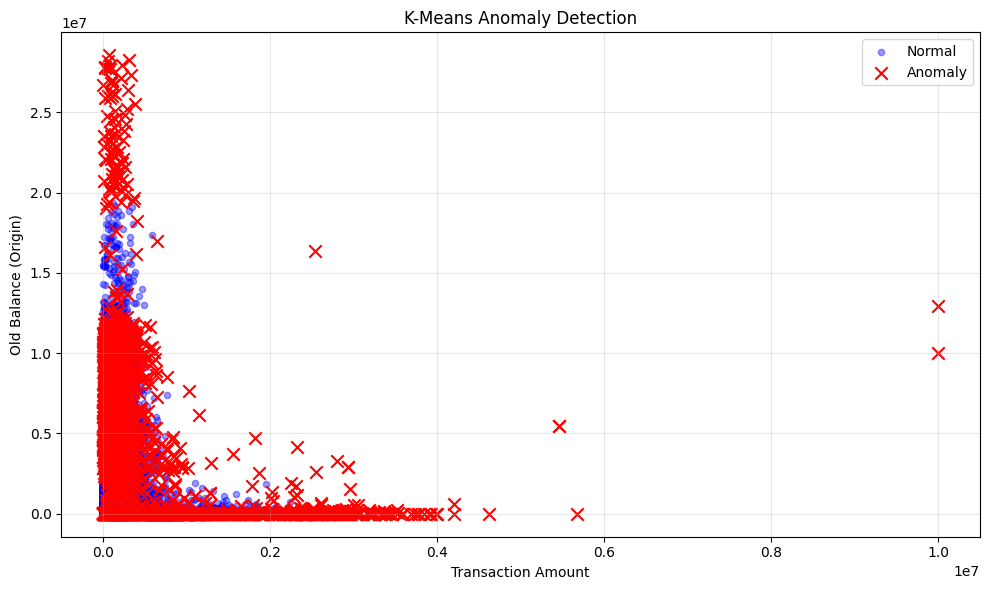

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

print("Original shape:", df.shape)
print("Fraud rate: {:.4f}%".format(df['isFraud'].mean() * 100))

# =========================
# HANDLE MISSING VALUES
# =========================
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# =========================
# FEATURE ENGINEERING
# =========================
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y_true = df["isFraud"]

# =========================
# SCALING
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================
# TRAIN K-MEANS (on normal data)
# =========================
X_normal = X_scaled[y_true == 0]

print(f"\nTraining K-Means on {len(X_normal)} normal samples...")

# You can try different values of k (5, 8, 10, 15...)
n_clusters = 8

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10,
    max_iter=300
)

kmeans.fit(X_normal)

# =========================
# ANOMALY SCORE = Distance to nearest centroid
# =========================
# Calculate distance of every point to its nearest cluster center
distances = kmeans.transform(X_scaled)          # shape: (n_samples, n_clusters)
anomaly_scores = np.min(distances, axis=1)      # distance to closest centroid

# =========================
# THRESHOLD
# =========================
# Using 95th percentile of scores from normal data
normal_scores = anomaly_scores[y_true == 0]
threshold = np.percentile(normal_scores, 95)

print(f"Threshold (95th percentile): {threshold:.6f}")

# Predictions
y_pred = (anomaly_scores > threshold).astype(int)

# =========================
# EVALUATION METRICS
# =========================
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)
roc_auc   = roc_auc_score(y_true, anomaly_scores)

cm = confusion_matrix(y_true, y_pred)

print("\n" + "="*55)
print("📊 K-Means Results")
print("="*55)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Fraud"]))

# =========================
# SAVE RESULTS
# =========================
results_df = pd.DataFrame({
    "Model": ["K-Means"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("kmeans_results.csv", index=False)
print("\n✅ Results saved to kmeans_results.csv")

# =========================
# VISUALIZATION
# =========================
plt.figure(figsize=(10, 6))

normal_mask = y_pred == 0
anomaly_mask = y_pred == 1

plt.scatter(df.loc[normal_mask, "amount"],
            df.loc[normal_mask, "oldbalanceOrg"],
            c='blue', alpha=0.4, label="Normal", s=20)

plt.scatter(df.loc[anomaly_mask, "amount"],
            df.loc[anomaly_mask, "oldbalanceOrg"],
            c='red', marker='x', s=80, label="Anomaly")

plt.xlabel("Transaction Amount")
plt.ylabel("Old Balance (Origin)")
plt.title("K-Means Anomaly Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Autoencoder + DBSCAN Hybrid Model

Original shape: (46125, 12)
Fraud rate: 0.2038%

----- Stage 1: Training Autoencoder -----
Epoch 1/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1761 - val_loss: 0.0269
Epoch 2/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0630 - val_loss: 0.0308
Epoch 3/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0524 - val_loss: 0.0307
Epoch 4/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0445 - val_loss: 0.0245
Epoch 5/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0403 - val_loss: 0.0260
Epoch 6/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0365 - val_loss: 0.0240
Epoch 7/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0341 - val_loss: 0.0192
Epoch 8/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0305 - val_loss: 0.0226
Epoch 9/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0300 - val_loss: 0.0308
Epoch 10/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0281 - val_loss: 0.0255
Epoch 11/50
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/

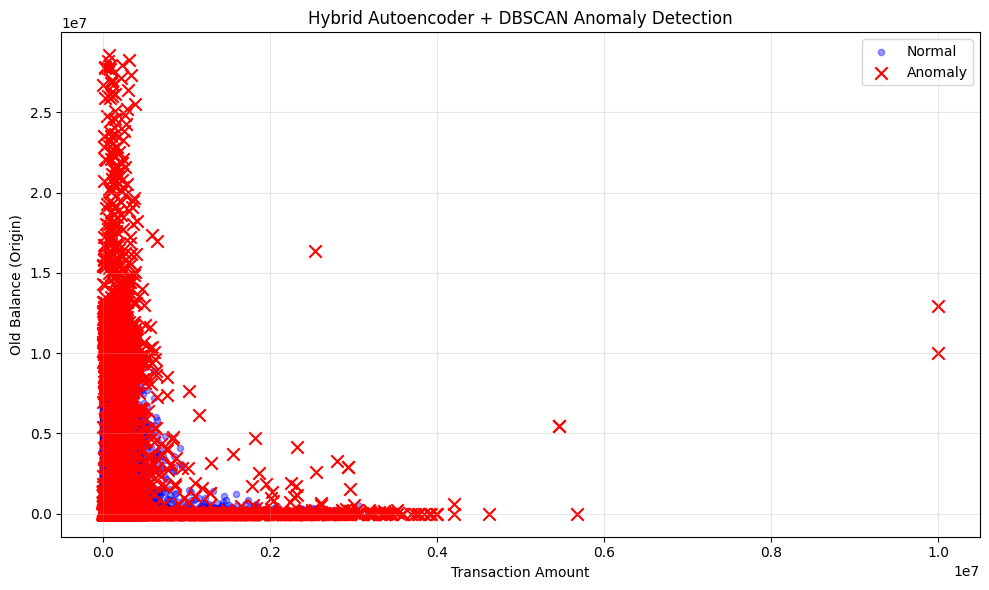

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# =========================
# LOAD DATASET
# =========================
df = pd.read_csv("dataset.csv")

print("Original shape:", df.shape)
print("Fraud rate: {:.4f}%".format(df['isFraud'].mean() * 100))

# =========================
# HANDLE MISSING VALUES
# =========================
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# =========================
# FEATURE ENGINEERING
# =========================
features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y_true = df["isFraud"].values

# =========================
# SCALING
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =========================================================
# STAGE 1: AUTOENCODER
# =========================================================
print("\n----- Stage 1: Training Autoencoder -----")

X_normal = X_scaled[y_true == 0]
X_train, X_val = train_test_split(X_normal, test_size=0.2, random_state=42)

input_dim = X_train.shape[1]
input_layer = Input(shape=(input_dim,))

x = Dense(64, activation='relu')(input_layer)
x = Dropout(0.1)(x)
x = Dense(32, activation='relu')(x)
x = Dropout(0.1)(x)
latent = Dense(16, activation='relu')(x)

x = Dense(32, activation='relu')(latent)
x = Dropout(0.1)(x)
x = Dense(64, activation='relu')(x)
output_layer = Dense(input_dim, activation='linear')(x)

autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer='adam', loss='mse')

early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1)

autoencoder.fit(
    X_train, X_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, X_val),
    callbacks=[early_stop],
    verbose=1
)

# Reconstruction Error
X_pred = autoencoder.predict(X_scaled, verbose=0)
reconstruction_error = np.mean(np.square(X_scaled - X_pred), axis=1)

# Threshold from normal data only
ae_threshold = np.percentile(reconstruction_error[y_true == 0], 95)
print(f"Autoencoder Threshold: {ae_threshold:.6f}")

# =========================================================
# STAGE 2: DBSCAN
# =========================================================
print("\n----- Stage 2: Running DBSCAN -----")

dbscan = DBSCAN(eps=0.8, min_samples=10, n_jobs=-1)
dbscan_labels = dbscan.fit_predict(X_scaled)

# -1 means noise (anomaly)
dbscan_anomaly = (dbscan_labels == -1).astype(int)

print(f"DBSCAN found {dbscan_anomaly.sum()} noise points")

# =========================================================
# STAGE 3: HYBRID COMBINATION
# =========================================================
print("\n----- Stage 3: Hybrid Combination -----")

# Method: Logical OR + Score Fusion
# 1. Hard prediction: Anomaly if AE says anomaly OR DBSCAN says noise
ae_anomaly = (reconstruction_error > ae_threshold).astype(int)
y_pred = np.logical_or(ae_anomaly, dbscan_anomaly).astype(int)

# 2. Combined Anomaly Score (for ROC-AUC)
# Normalize both scores between 0 and 1
ae_score_norm = (reconstruction_error - reconstruction_error.min()) / (reconstruction_error.max() - reconstruction_error.min() + 1e-8)

# For DBSCAN we create a simple score (1 for noise, 0 for normal)
dbscan_score = dbscan_anomaly.astype(float)

# Weighted fusion (you can change weights)
combined_score = 0.6 * ae_score_norm + 0.4 * dbscan_score

# =========================
# EVALUATION
# =========================
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)
roc_auc   = roc_auc_score(y_true, combined_score)

cm = confusion_matrix(y_true, y_pred)

print("\n" + "="*60)
print("📊 Hybrid Autoencoder + DBSCAN Results")
print("="*60)
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\n📌 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Fraud"]))

# =========================
# SAVE RESULTS
# =========================
results_df = pd.DataFrame({
    "Model": ["Hybrid Autoencoder + DBSCAN"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc]
})

results_df.to_csv("hybrid_ae_dbscan_results.csv", index=False)
print("\n✅ Results saved to hybrid_ae_dbscan_results.csv")

# =========================
# VISUALIZATION
# =========================
plt.figure(figsize=(10, 6))

normal_mask = y_pred == 0
anomaly_mask = y_pred == 1

plt.scatter(df.loc[normal_mask, "amount"],
            df.loc[normal_mask, "oldbalanceOrg"],
            c='blue', alpha=0.4, label="Normal", s=20)

plt.scatter(df.loc[anomaly_mask, "amount"],
            df.loc[anomaly_mask, "oldbalanceOrg"],
            c='red', marker='x', s=80, label="Anomaly")

plt.xlabel("Transaction Amount")
plt.ylabel("Old Balance (Origin)")
plt.title("Hybrid Autoencoder + DBSCAN Anomaly Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler, LabelEncoder

# =========================
# Load and prepare data
# =========================
df = pd.read_csv("dataset.csv")
df = df.dropna(subset=['isFraud'])
df['isFraud'] = df['isFraud'].astype(int)

features = [
    "step", "type", "amount",
    "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest"
]

le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

X = df[features]
y = df["isFraud"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train only on normal data
X_normal = X_scaled[y == 0]

model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.01)
model.fit(X_normal)

# =========================
# Custom Scorer
# =========================
def my_scorer(estimator, X, y_true):
    scores = -estimator.decision_function(X)
    return np.corrcoef(scores, y_true)[0, 1]

# =========================
# Permutation Importance
# =========================
result = permutation_importance(
    model,
    X_scaled,
    y,
    n_repeats=5,
    random_state=42,
    scoring=my_scorer,
    n_jobs=-1
)

importances = result.importances_mean
indices = np.argsort(importances)[::-1]   # Highest importance on top

# =========================
# Plot (Exact same style as Random Forest)
# =========================
plt.figure(figsize=(10, 6))
plt.barh(range(len(indices)), importances[indices], color='#4B0082')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel("Importance")
plt.title("One-Class SVM Feature Importances")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()   # Highest importance at the top
plt.tight_layout()
plt.savefig("OneClassSVM_Feature_Importance.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Chart saved as: OneClassSVM_Feature_Importance.png")